# Graph exploration

In [53]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

NODES_PATH = Path("..", "dataset", "node_features.csv")
EDGES_PATH = Path("..", "dataset", "edges.csv")

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load and sanity-check the data

In [54]:
nodes = pd.read_csv(NODES_PATH)
edges = pd.read_csv(EDGES_PATH)

print(f"nodes: {nodes.shape}, edges: {edges.shape}")
display(nodes.head())
display(edges.head())

nodes: (7571, 16), edges: (21809, 3)


,acpl,accuracy,num_moves,frac_blunders,frac_mistakes,frac_inaccuracies,avg_move_time,last_theory_ply,target_rating,username,win_streak,loss_streak,num_games,win_rate,loss_rate,draw_rate
0,59.916667,78.500000,67.716667,0.032208,0.025386,0.056310,0.013222,4.800000,1805.0,simo_ecn,18,11,4591,0.485951,0.493357,0.020693
1,64.950000,76.783333,85.433333,0.036528,0.023679,0.048051,0.025250,3.550000,1653.0,Kazenkoekk,7,7,574,0.479094,0.459930,0.060976
2,66.083333,76.750000,60.416667,0.036955,0.018726,0.051871,0.009440,5.000000,1180.0,chentai2015,8,10,504,0.436508,0.523810,0.039683
3,64.500000,73.466667,61.433333,0.036701,0.021028,0.039526,0.013087,3.450000,1551.0,alopezpr,16,11,4156,0.490857,0.487247,0.021896
4,47.800000,82.033333,71.750000,0.026958,0.017767,0.043187,0.027324,5.466667,1789.0,Rathh_Nadnebesnie,11,6,518,0.554054,0.403475,0.042471


,from,to,points
0,anonimochess100,WaldAld,1.0
1,Yason1,anonimochess100,1.0
2,anonimochess100,shekharfromcal,1.0
3,WinandFail,anonimochess100,1.0
4,anonimochess100,Stelog,1.0


In [55]:
display(nodes.describe().T)
print("Missing values per node column:")
print(nodes.isna().sum()[lambda s: s > 0])

/home/ruben/Projects/GraphML-Lichess/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
acpl,7571.0,66.048211,17.459098,13.600000,54.366667,64.050000,74.783333,2.560000e+02
accuracy,7571.0,76.168879,5.293095,41.900000,73.149468,76.500000,79.650000,9.610000e+01
num_moves,7571.0,66.557490,8.687624,36.933333,60.500000,66.083333,72.200000,1.116833e+02
frac_blunders,7571.0,0.038233,0.011369,0.002340,0.030634,0.037235,0.044629,1.240533e-01
frac_mistakes,7571.0,0.022666,0.005467,0.001389,0.019061,0.022246,0.025900,5.345604e-02
frac_inaccuracies,7571.0,0.048729,0.008803,0.003639,0.042931,0.048170,0.053862,9.473249e-02
avg_move_time,7571.0,inf,NaN,0.004550,0.013097,0.016393,0.020987,inf
last_theory_ply,7571.0,4.648067,0.857041,1.071429,4.116667,4.727273,5.250000,7.058824e+00
target_rating,7571.0,1532.263373,308.126084,400.000000,1326.000000,1539.000000,1734.000000,2.591000e+03
win_streak,7571.0,9.900013,4.511768,1.000000,8.000000,9.000000,12.000000,1.050000e+02


Missing values per node column:
Series([], dtype: int64)


In [56]:
node_ids = set(nodes["username"])
edge_ids = set(edges["from"]) | set(edges["to"])

print("duplicate usernames in nodes:     ", nodes["username"].duplicated().sum())
print("duplicate (from, to) pairs:       ", edges.duplicated(["from", "to"]).sum())
print("self-loops:                       ", (edges["from"] == edges["to"]).sum())
print("edge endpoints missing from nodes:", len(edge_ids - node_ids))
print("nodes with no edges at all:       ", len(node_ids - edge_ids))

duplicate usernames in nodes:      0
duplicate (from, to) pairs:        6134
self-loops:                        0
edge endpoints missing from nodes: 0
nodes with no edges at all:        32


## 2. Build the graph

In [57]:
edges_dedup = edges.drop_duplicates(["from", "to"], keep="first").reset_index(drop=True)

G = nx.DiGraph()
G.add_nodes_from(nodes.drop_duplicates("username").set_index("username").to_dict("index").items())
G.add_weighted_edges_from(edges_dedup[["from", "to", "points"]].itertuples(index=False, name=None))

UG = nx.Graph(G)   # undirected view, used for clustering / communities
print(G)

DiGraph with 7571 nodes and 15675 edges


## 3. Global characteristics

In [58]:
n, m = G.number_of_nodes(), G.number_of_edges()
summary = {
    "nodes": n,
    "edges": m,
    "density": nx.density(G),
    "avg degree": 2 * UG.number_of_edges() / n,
    "isolated nodes": nx.number_of_isolates(G),
    "self-loops": nx.number_of_selfloops(G),
    "total points": edges_dedup["points"].sum(),
}
summary["reciprocity"] = nx.reciprocity(G)
wcc = list(nx.weakly_connected_components(G))
scc = list(nx.strongly_connected_components(G))
summary["weak components"] = len(wcc)
summary["largest weak component"] = max(map(len, wcc))
summary["strong components"] = len(scc)
summary["largest strong component"] = max(map(len, scc))
summary["avg clustering (undirected)"] = nx.average_clustering(UG)
summary["transitivity"] = nx.transitivity(UG)

pd.Series(summary, name="value").to_frame()

,value
nodes,7571.000000
edges,15675.000000
density,0.000274
avg degree,3.656056
isolated nodes,32.000000
self-loops,0.000000
total points,19387.000000
reciprocity,0.234131
weak components,63.000000
largest weak component,7463.000000


In [59]:
scc_nodes = max(nx.strongly_connected_components(G), key=len)
wcc_nodes = max(nx.weakly_connected_components(G), key=len)
SCC = UG.subgraph(scc_nodes)
WCC = UG.subgraph(wcc_nodes)

more_summary = {
    "diameter (max scc)": nx.diameter(SCC),
    "diameter (max wcc)": nx.diameter(WCC),
    "avg_shortest_path (max scc)": round(nx.average_shortest_path_length(SCC), 3),
    "avg_shortest_path (max wcc)": round(nx.average_shortest_path_length(WCC), 3),
    
}

pd.Series(more_summary, name="value").to_frame()

,value
diameter (max scc),15.000
diameter (max wcc),26.000
avg_shortest_path (max scc),6.503
avg_shortest_path (max wcc),7.515


## 4. Degree and strength distributions

In [60]:
metrics = pd.DataFrame(index=list(G.nodes))
metrics["in_degree"] = pd.Series(dict(G.in_degree()))
metrics["out_degree"] = pd.Series(dict(G.out_degree()))
metrics["in_points"] = pd.Series(dict(G.in_degree(weight="weight")))
metrics["out_points"] = pd.Series(dict(G.out_degree(weight="weight")))
metrics["degree"] = pd.Series(dict(UG.degree()))
metrics["strength"] = pd.Series(dict(UG.degree(weight="weight")))
metrics.describe().T

,count,mean,std,min,25%,50%,75%,max
in_degree,7571.0,2.070400,1.817553,0.0,1.0,2.0,3.0,24.0
out_degree,7571.0,2.070400,1.835993,0.0,1.0,2.0,3.0,25.0
in_points,7571.0,2.560692,3.465986,0.0,1.0,2.0,3.0,57.0
out_points,7571.0,2.560692,3.563166,0.0,1.0,2.0,3.0,75.0
degree,7571.0,3.656056,2.451548,0.0,2.0,3.0,4.0,38.0
strength,7571.0,4.303923,4.075342,0.0,2.0,3.0,5.0,79.0


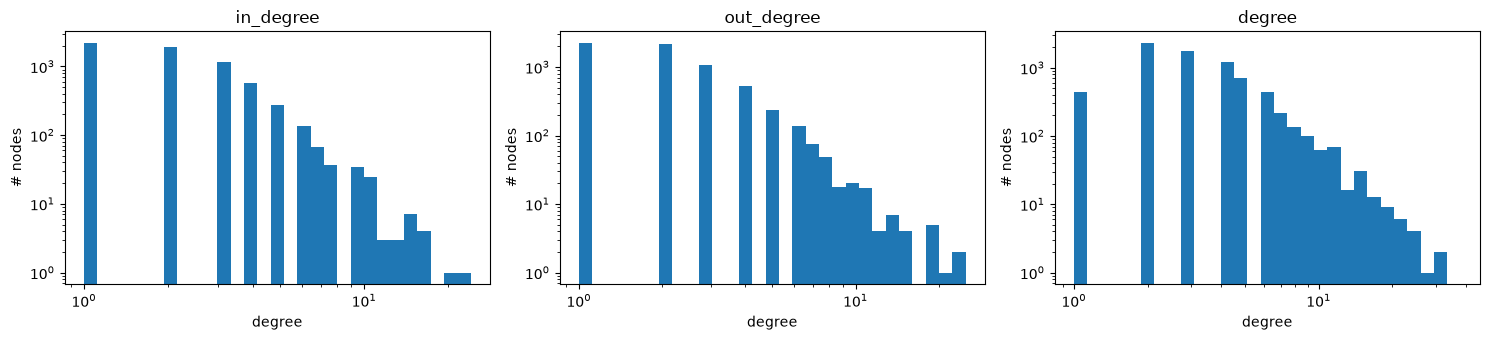

In [61]:
cols = [c for c in ["in_degree", "out_degree", "degree"] if c in metrics]
fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.5))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, cols):
    vals = metrics[c][metrics[c] > 0]
    bins = np.logspace(0, np.log10(max(vals.max(), 2)), 30)
    ax.hist(vals, bins=bins)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(c); ax.set_xlabel("degree"); ax.set_ylabel("# nodes")
plt.tight_layout(); plt.show()

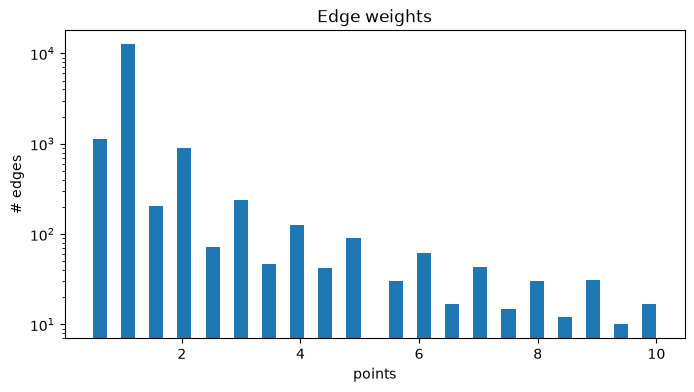

In [62]:
# Edge weight distribution
fig, ax = plt.subplots()
ax.hist(edges_dedup["points"], bins=40)
ax.set_yscale("log"); ax.set_xlabel("points"); ax.set_ylabel("# edges"); ax.set_title("Edge weights")
plt.show()

## 5. Centrality

In [63]:
metrics["pagerank"] = pd.Series(nx.pagerank(G, weight="weight"))

# Betweenness is O(n*m); approximate with k sampled sources on larger graphs.
k = None if n <= 1000 else 300
metrics["betweenness"] = pd.Series(nx.betweenness_centrality(UG, k=k, seed=42))

metrics["clustering"] = pd.Series(nx.clustering(UG))
metrics.sort_values("pagerank", ascending=False).head(10)

,in_degree,out_degree,in_points,out_points,degree,strength,pagerank,betweenness,clustering
Chandan_Kumar_Sinha,23,10,37.5,12.5,27,40.5,0.001740,0.018199,0.014245
sdbhau,4,4,5.0,4.0,7,7.0,0.001644,0.005997,0.000000
somar21,7,3,7.0,4.0,9,10.0,0.001592,0.002157,0.027778
Dedulia_Sasha,14,16,29.5,26.5,20,38.5,0.001363,0.008224,0.015789
perfectfather,14,14,24.0,34.0,20,36.0,0.001279,0.009930,0.010526
gsingh,4,1,3.5,0.5,4,3.5,0.001250,0.000216,0.000000
mudshark2,20,1,20.0,1.0,21,21.0,0.001230,0.014244,0.004762
kiketacea,8,11,18.0,26.0,12,26.0,0.001227,0.002662,0.045455
maedachess,2,1,1.5,0.5,2,1.5,0.001169,0.000163,0.000000
Aohane,3,1,4.0,1.0,3,4.0,0.001167,0.000297,0.000000


In [64]:
metrics.sort_values("betweenness", ascending=False).head(10)[["degree", "strength", "betweenness", "pagerank"]]

,degree,strength,betweenness,pagerank
Scobiwan,38,45.5,0.025784,0.001120
Johnyfrodo,33,39.5,0.019357,0.000738
Chandan_Kumar_Sinha,27,40.5,0.018199,0.001740
Pogreb-Sergey,30,36.0,0.017347,0.000978
malhamza999,22,22.0,0.015348,0.000281
Khristof,20,29.0,0.015324,0.001047
jonman_t99,19,20.0,0.014824,0.000583
IlliaSav,18,18.0,0.014553,0.000545
mudshark2,21,21.0,0.014244,0.001230
jc241971,17,17.5,0.014059,0.000685


## 6. Assortativity and communities

In [65]:
rated = [v for v, d in G.nodes(data=True) if pd.notna(d.get("target_rating"))]
assortativity_stats = {
    "degree assortativity": round(nx.degree_assortativity_coefficient(G), 4),
    "target_rating assortativity:": round(nx.numeric_assortativity_coefficient(G.subgraph(rated), "target_rating"), 4)
}

pd.Series(assortativity_stats, name="value").to_frame()

,value
degree assortativity,0.1028
target_rating assortativity:,0.7409


In [66]:
communities = nx.community.louvain_communities(UG, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
print(f"{len(communities)} communities, modularity = {nx.community.modularity(UG, communities, weight='weight'):.3f}")

comm_map = {v: i for i, c in enumerate(communities) for v in c}
metrics["community"] = pd.Series(comm_map)

attrs = nodes.drop_duplicates("username").set_index("username")
joined = metrics.join(attrs)
top = joined[joined["community"] < 10]
top.groupby("community").agg(
    size=("degree", "size"),
    mean_rating=("target_rating", "mean"),
    mean_acpl=("acpl", "mean"),
    mean_win_rate=("win_rate", "mean"),
    mean_degree=("degree", "mean"),
)

106 communities, modularity = 0.717


,size,mean_rating,mean_acpl,mean_win_rate,mean_degree
community,,,,,
0,942,1724.917197,61.219423,0.487019,4.167728
1,547,1528.085923,59.458147,0.489681,4.685558
2,522,1543.032567,67.333399,0.482165,4.057471
3,502,1535.199203,61.920640,0.482623,4.480080
4,414,1763.417874,56.016221,0.487117,4.589372
5,336,2020.854167,48.799512,0.511145,3.419643
6,330,1509.466667,66.809948,0.485179,3.742424
7,300,1315.193333,73.477363,0.477370,3.026667
8,283,1258.155477,74.532032,0.473672,3.102473


## 7. Do node stats relate to network position?

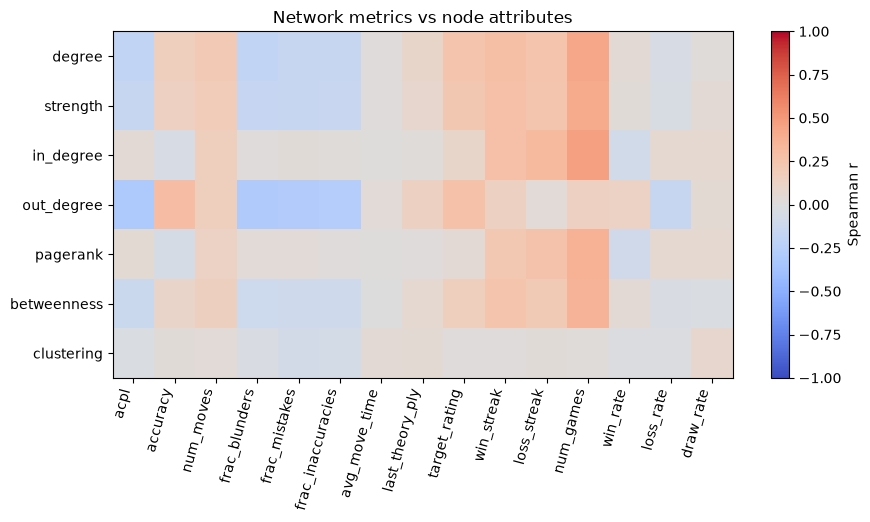

In [67]:
net_cols = [c for c in ["degree", "strength", "in_degree", "out_degree", "pagerank", "betweenness", "clustering"] if c in joined]
attr_cols = attrs.select_dtypes("number").columns.tolist()

corr = joined[net_cols + attr_cols].corr(method="spearman").loc[net_cols, attr_cols]

fig, ax = plt.subplots(figsize=(1 + 0.6 * len(attr_cols), 1 + 0.5 * len(net_cols)))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(attr_cols)), attr_cols, rotation=75, ha="right")
ax.set_yticks(range(len(net_cols)), net_cols)
fig.colorbar(im, label="Spearman r")
ax.set_title("Network metrics vs node attributes")
plt.show()

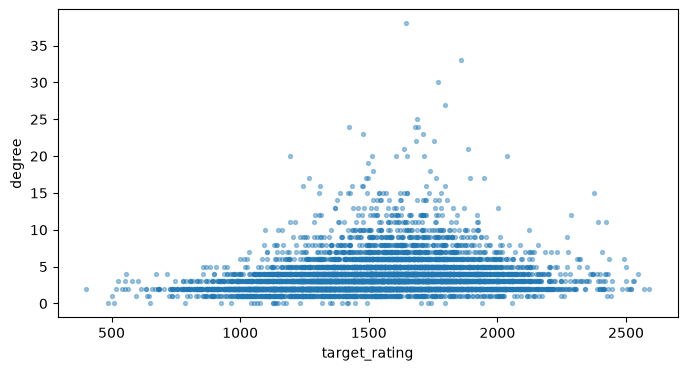

In [68]:
# Example scatter: rating vs. connectivity
fig, ax = plt.subplots()
ax.scatter(joined["target_rating"], joined["degree"], s=8, alpha=0.4)
ax.set_xlabel("target_rating")
ax.set_ylabel("degree"); 
plt.show()

## 8. Misc

In [72]:
# How tree-like is the graph?
deg_u = dict(UG.degree())
n_nodes = UG.number_of_nodes()
n_leaves = sum(d == 1 for d in deg_u.values())
core2 = nx.k_core(UG, 2).number_of_nodes()   # nodes that sit on/between cycles
n_cycles = UG.number_of_edges() - n_nodes + nx.number_connected_components(UG)  # cyclomatic number

stats = {
    "leaves (degree 1)": f"{n_leaves / n_nodes:.1%}",
    "in 2-core (not a leaf/tree branch)": f"{core2 / n_nodes:.1%}",
    "independent cycles": n_cycles,
    "edges per node": round(UG.number_of_edges() / n_nodes, 3),   # ~1 means tree-like
}
stats["sinks (out_degree 0)"] = f"{(metrics['out_degree'] == 0).mean():.1%}"
stats["sources (in_degree 0)"] = f"{(metrics['in_degree'] == 0).mean():.1%}"
pd.Series(stats, name="value").to_frame()

,value
leaves (degree 1),5.9%
in 2-core (not a leaf/tree branch),89.2%
independent cycles,6332
edges per node,1.828
sinks (out_degree 0),13.1%
sources (in_degree 0),14.6%


In [76]:
core = max(nx.strongly_connected_components(G), key=len)
anchor = next(iter(core))

IN  = (nx.ancestors(G, anchor) | {anchor}) - core     # can reach the core, can't be reached from it
OUT = (nx.descendants(G, anchor) | {anchor}) - core   # reachable from the core, can't reach it
other = set(G) - core - IN - OUT                      # tendrils, tubes, disconnected pieces

bowtie = pd.Series({"core (giant SCC)": len(core), "IN": len(IN), "OUT": len(OUT), "other": len(other)})
display(pd.DataFrame({"nodes": bowtie, "share": (bowtie / G.number_of_nodes()).map("{:.1%}".format)}))

,nodes,share
core (giant SCC),3736,49.3%
IN,1506,19.9%
OUT,1328,17.5%
other,1001,13.2%
